In [1]:
%load_ext autoreload
%autoreload 2

## Load Raw

In [17]:
from smlm.io import load_raw
from smlm import viz

# EMCCD 的 SIF —— em_gain 自动从头信息读出
src = r"/Volumes/SMILeSSD/SPARK/20261009/SPARK Cy3_avidin_532nm_2mW_0p1S_3000frames_fov1.sif"
raw = load_raw(src)
print(raw.data.shape, raw.n_frames, raw.em_gain, raw.exposure_time)
pixel_size=106.6 # nm/pixel
# sCMOS 的 TIF,每 5 帧取 1 帧
#raw = load_raw("cell01.tif", interval=5)
#print(raw.images.shape, raw.em_gain)   # em_gain 为 None

(2000, 512, 512) 2000 300.0 0.1


In [18]:
# 接下来交给 camera 层转光子
from smlm.camera import EMCCD
cam = EMCCD(conv_factor=5.75, em_gain=raw.em_gain)
image = cam.process(raw, pixel_size=106.6)

In [16]:
# 保存转化后的光子图像为 tif(与源文件同目录同名, 加 _photons 后缀)
import os
from smlm.io import save_tif
dst = os.path.splitext(src)[0] + "_photons.tif"
save_tif(image, dst)

[io] saved tif (2000, 512, 512) -> /Volumes/SMILeSSD/SPARK/20261009/SPARK Cy3_avidin_532nm_2mW_0p1S_3000frames_fov3_photons.tif


'/Volumes/SMILeSSD/SPARK/20261009/SPARK Cy3_avidin_532nm_2mW_0p1S_3000frames_fov3_photons.tif'

## Preprocessing

In [19]:
from smlm.imgprocess import Pipeline, Crop, SelectFrames
# 预处理: 裁剪 ROI + 选前 2000 帧
prep = Pipeline(Crop(y=(100, 400), x=(100, 400)),
                SelectFrames(stop=1999))
stack = prep(image)

## Detect

In [20]:
from smlm.localize import LocalMaxDetector
import numpy as np

detector=LocalMaxDetector(k_sigma=3.5, edge=5, f_em=np.sqrt(2),
                 bg_window=15, max_size=7, min_neighbors=2, verbose=True)
cand = detector.detect(stack)

processing frame 50 / 1999
processing frame 100 / 1999
processing frame 150 / 1999
processing frame 200 / 1999
processing frame 250 / 1999
processing frame 300 / 1999
processing frame 350 / 1999
processing frame 400 / 1999
processing frame 450 / 1999
processing frame 500 / 1999
processing frame 550 / 1999
processing frame 600 / 1999
processing frame 650 / 1999
processing frame 700 / 1999
processing frame 750 / 1999
processing frame 800 / 1999
processing frame 850 / 1999
processing frame 900 / 1999
processing frame 950 / 1999
processing frame 1000 / 1999
processing frame 1050 / 1999
processing frame 1100 / 1999
processing frame 1150 / 1999
processing frame 1200 / 1999
processing frame 1250 / 1999
processing frame 1300 / 1999
processing frame 1350 / 1999
processing frame 1400 / 1999
processing frame 1450 / 1999
processing frame 1500 / 1999
processing frame 1550 / 1999
processing frame 1600 / 1999
processing frame 1650 / 1999
processing frame 1700 / 1999
processing frame 1750 / 1999
proce

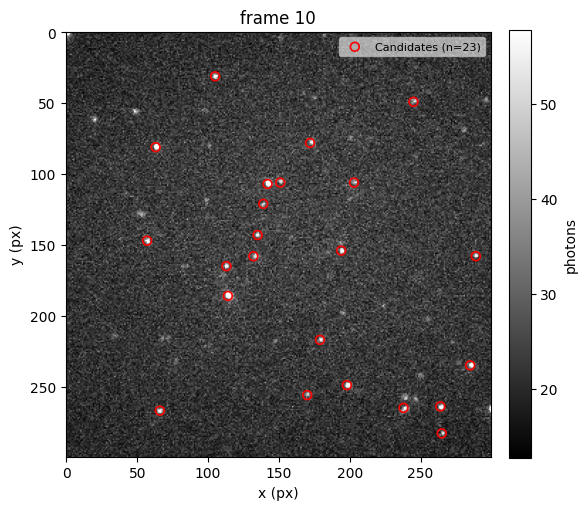

In [21]:
ax = viz.overlay_points(stack, cand, frames=10, color='r', marker='o')

## Localize

In [22]:
from smlm.localize import MLELocalizer
localizer = MLELocalizer(edge=5, F_EM=np.sqrt(2.0), use_pixel=False,
                 use_gradient=True, n_jobs=8, verbose=True)
locs = localizer.localize(stack,cand)

8170 / 8170 candidates in-range, fitting...


MLE fitting: 100%|██████████| 8170/8170 [00:58<00:00, 140.11it/s]


MLE fitting done in 58.46s (7.16 ms/loc)
MLE done, 8170 localizations kept.


[filter] removed 2 / 8170 (0.02%), kept 8168


(<Figure size 1000x800 with 4 Axes>,
 array([<Axes: title={'center': 'Photons'}, xlabel='Photons (photons/molecule)', ylabel='count'>,
        <Axes: title={'center': 'Background'}, xlabel='Background (photons/pixel)', ylabel='count'>,
        <Axes: title={'center': 'PSF width'}, xlabel='PSF width (pixel)', ylabel='count'>,
        <Axes: title={'center': 'Localization precision'}, xlabel='Localization precision (nm)', ylabel='count'>],
       dtype=object))

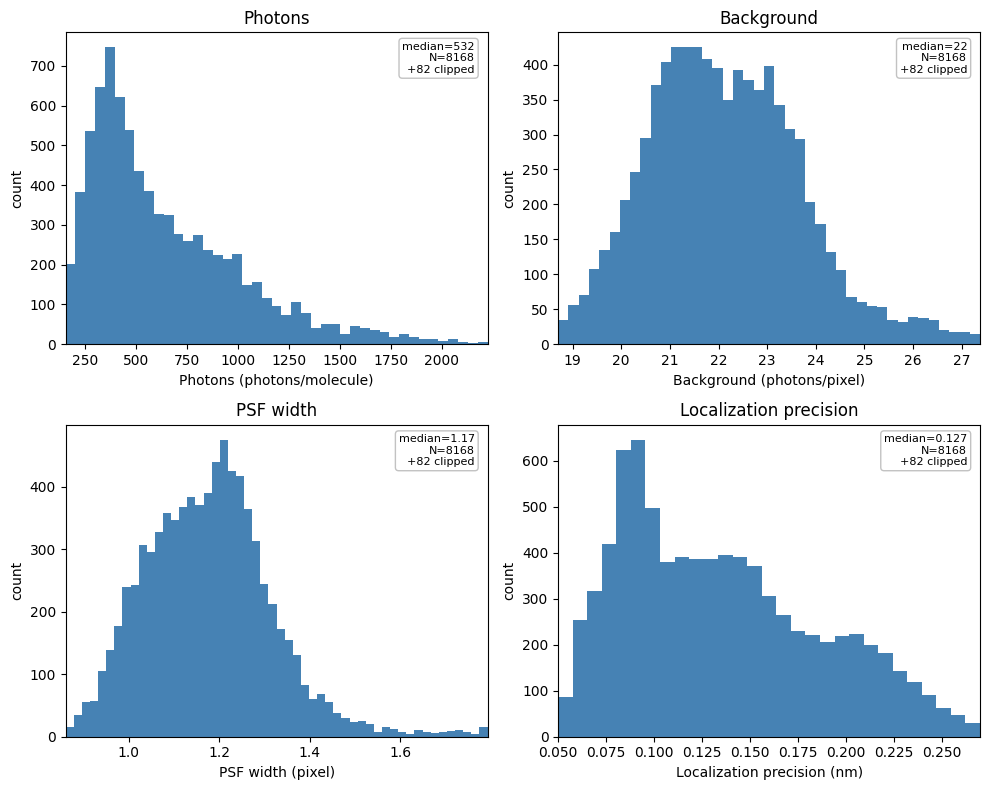

In [23]:
from smlm.localize import filter_locs
from smlm.viz import plot_distributions
locs = filter_locs(locs)
plot_distributions(locs)

## Detect+Localize

In [ ]:
from smlm.localize import ClassicalPipeline, LocalMaxDetector, MLELocalizer, filter_locs
from smlm.io import run_cached
import numpy as np
method = ClassicalPipeline(
    detector=LocalMaxDetector(k_sigma=3.8, edge=5, f_em=np.sqrt(2),
                 bg_window=15, max_size=7, min_neighbors=2, verbose=True),
    localizer = MLELocalizer(edge=5, F_EM=np.sqrt(2.0), use_pixel=False,
                 use_gradient=True, n_jobs=1, verbose=True),
)
locs = run_cached(method, stack, src)   # 首次计算并保存, 之后直接读盘

Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x109898790>>
Traceback (most recent call last):
  File "/opt/anaconda3/envs/d2l/lib/python3.9/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


In [ ]:
from smlm.viz import plot_distributions
locs = filter_locs(locs)
plot_distributions(locs)

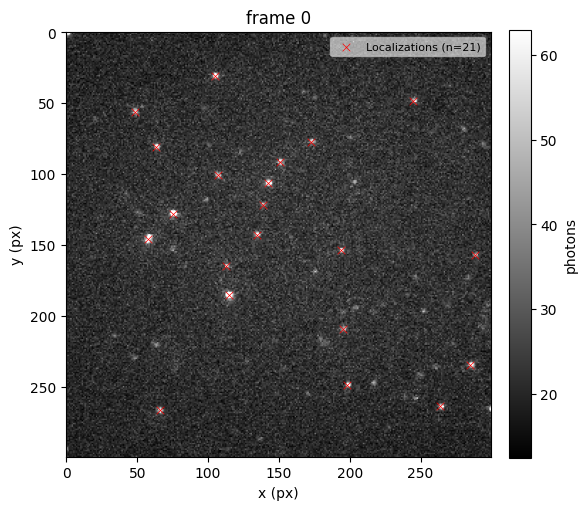

In [14]:
ax = viz.overlay_points(stack, locs, frames=0, color='r', marker='x', size=30, linewidth = 0.5, unit='pixel',pixel_size=pixel_size)

## Drift Correction

In [24]:
from smlm.drift import CloudDriftEstimator
from smlm.imgprocess import DriftCorrector     # 校正侧已移至 imgprocess

# 1) 估计(只需要定位)
uncertainty = np.median(locs.lp)
est = CloudDriftEstimator(frames_per_seg=10, uncertainty=uncertainty, do_stage2=True)
drift_trace = est.estimate(locs, n_frames=stack.n_frames)
#drift_trace = DriftTrace.zeros(n_frames = stack.n_frames, pixel_size=pixel_size)  # 测试零漂移占位

# 2) 校正图像 + 定位(带缓冲裁切, 与 MATLAB correctDrift 对齐)
corr = DriftCorrector(crop=(257, 257), edge=5)
corr_image, corr_locs, keep_idx = corr.apply(trace=drift_trace, image=stack, locs=locs)

=== Stage 1: first segment as reference ===
Reference seg 0 (frames 0-9): 212 locs
  seg  1 (f10-19): 5 iters, 175 pairs
  seg  2 (f20-29): 5 iters, 140 pairs
  seg  3 (f30-39): 4 iters, 100 pairs
  seg  4 (f40-49): 3 iters, 95 pairs
  seg  5 (f50-59): 3 iters, 77 pairs
  seg  6 (f60-69): 2 iters, 61 pairs
  seg  7 (f70-79): 3 iters, 61 pairs
  seg  8 (f80-89): 2 iters, 61 pairs
  seg  9 (f90-99): 2 iters, 54 pairs
  seg 10 (f100-109): 2 iters, 54 pairs
  seg 11 (f110-119): 1 iters, 54 pairs
  seg 12 (f120-129): 1 iters, 55 pairs
  seg 13 (f130-139): 3 iters, 41 pairs
  seg 14 (f140-149): 2 iters, 41 pairs
  seg 15 (f150-159): 1 iters, 36 pairs
[Warn] seg 16 locs 58<60, skip.
  seg 17 (f170-179): 1 iters, 35 pairs
  seg 18 (f180-189): 2 iters, 36 pairs
  seg 19 (f190-199): 1 iters, 36 pairs
  seg 20 (f200-209): 2 iters, 35 pairs
  seg 21 (f210-219): 1 iters, 36 pairs
  seg 22 (f220-229): 2 iters, 35 pairs
  seg 23 (f230-239): 1 iters, 35 pairs
  seg 24 (f240-249): 1 iters, 35 pairs
[Wa

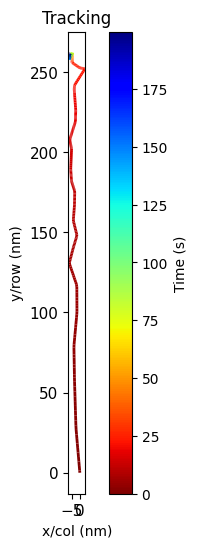

In [25]:
from smlm.viz import plot_drift
fig, ax = plot_drift(drift_trace, ex_time=raw.exposure_time,unit='nm',pixel_size=pixel_size) 


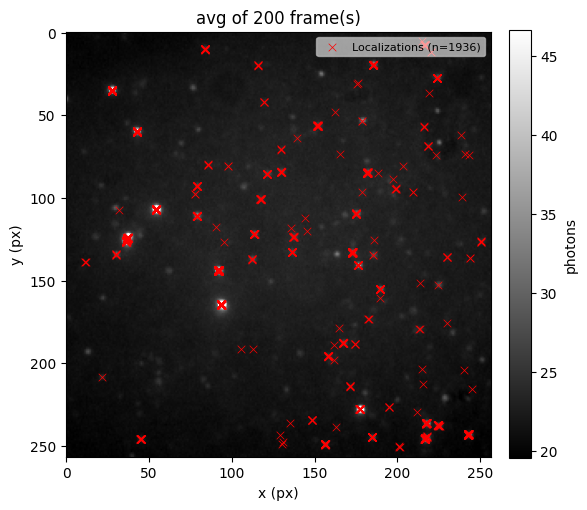

In [27]:
ax = viz.overlay_points(corr_image, corr_locs, frames=np.arange(0,200), color='r', marker='x', size=30, linewidth = 0.5)

## Emitter Analysis

In [40]:
from smlm.emitter import analyze_emitters

emitters, emitters_raw = analyze_emitters(
    corr_locs, n_frames=None,
    search_radius=2,
    max_gap=300,
    min_frames=5,
    ecc_th=3.5,
    first_frame_range=(0,200),
    motion='static',do_merge=False
)

连接得到 713 个 emitter
MinDurationFilter: 保留 176 / 713
FirstFrameFilter: 保留 46 / 176
EccentricityFilter: 保留 39 / 46


In [41]:
from smlm.emitter import collect_statistics
stats = collect_statistics(emitters, locs, raw.exposure_time, 0)


(<Figure size 1100x700 with 6 Axes>,
 array([<Axes: title={'center': 'Survival time'}, xlabel='Survival time (s)', ylabel='count'>,
        <Axes: title={'center': 'Locs per emitter'}, xlabel='Locs per emitter (count)', ylabel='count'>,
        <Axes: title={'center': 'Duty cycle'}, xlabel='Duty cycle', ylabel='count'>,
        <Axes: title={'center': 'Total photons'}, xlabel='Total photons (photons)', ylabel='count'>,
        <Axes: title={'center': 'Eccentricity'}, xlabel='Eccentricity', ylabel='count'>,
        <Axes: title={'center': 'Mean PSF width'}, xlabel='Mean PSF width (pixel)', ylabel='count'>],
       dtype=object))

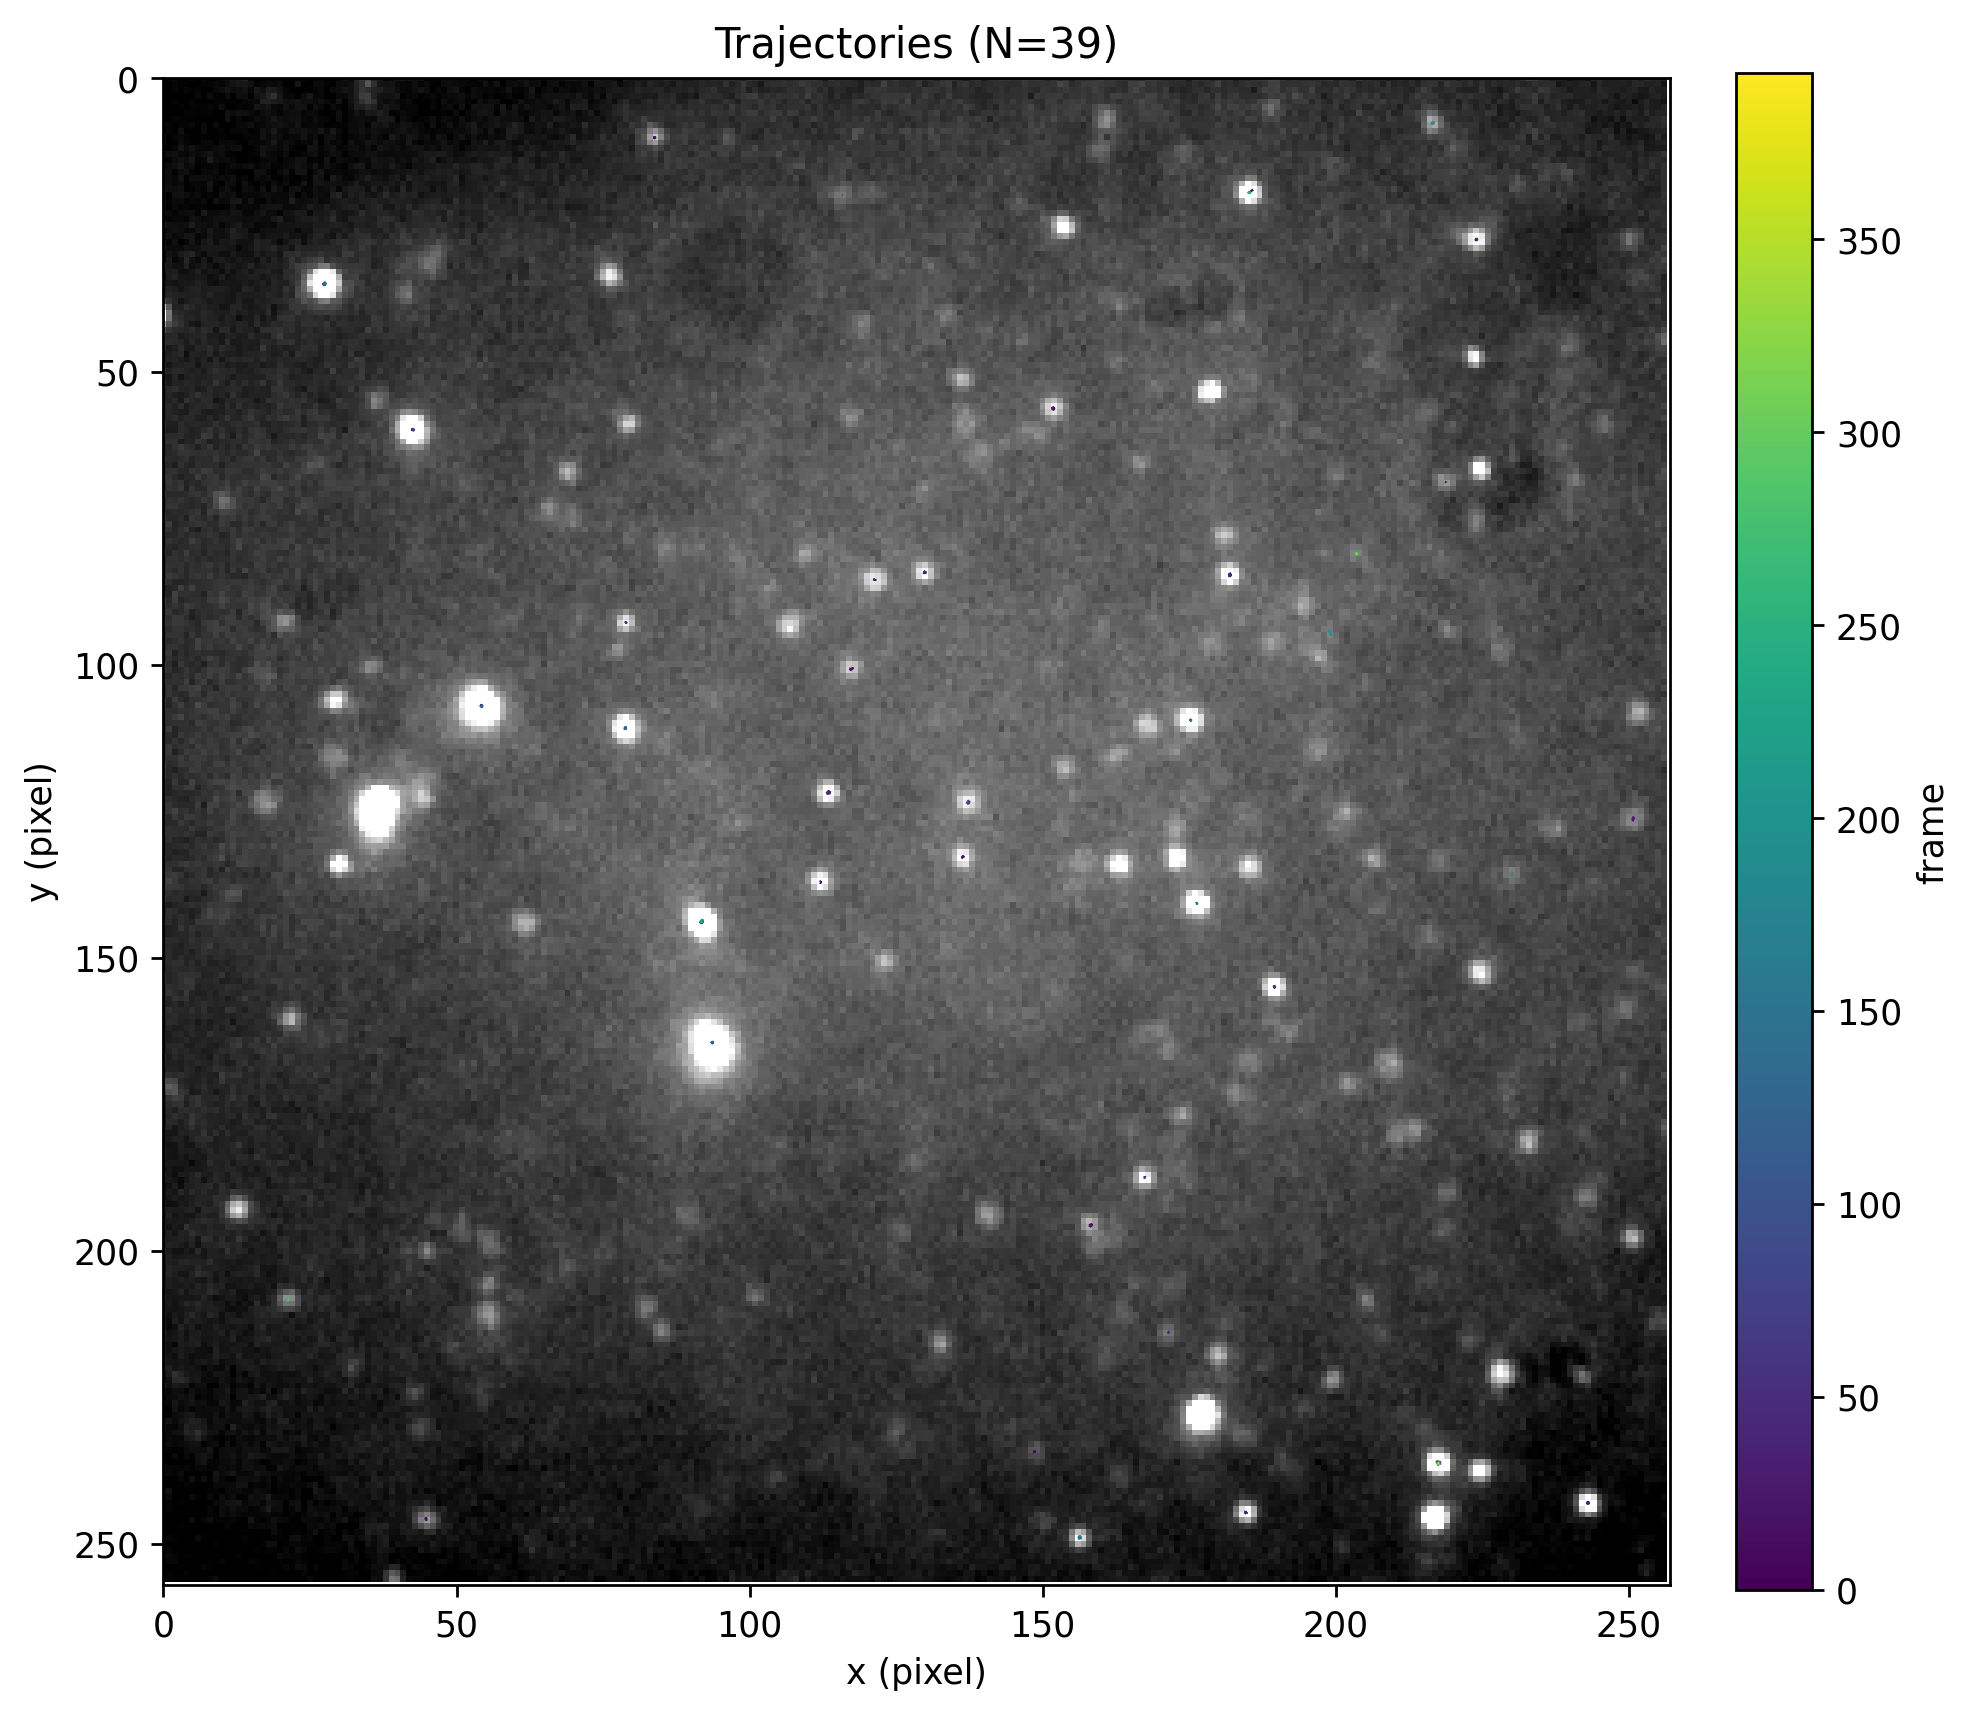

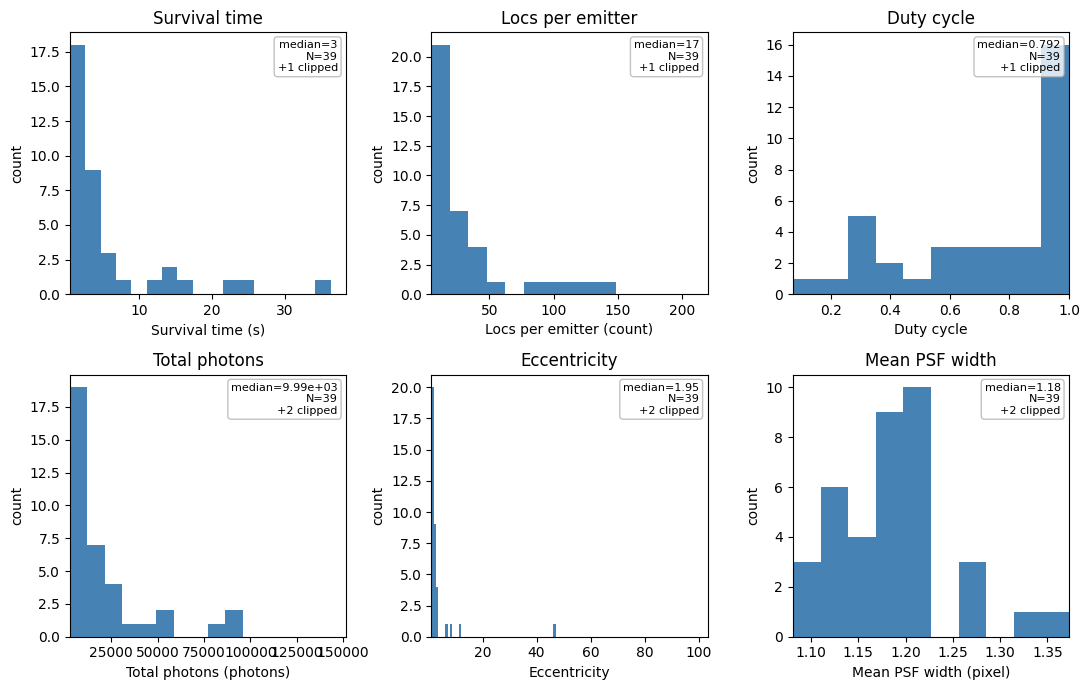

In [42]:
from smlm.viz import plot_trajectories, plot_bleaching_summary, plot_emitter_stats
plot_trajectories(corr_image.data, emitters, linewidth=0.7, frame_idx=np.arange(0, 200), dpi=250)
plot_emitter_stats(stats)

## Trace Extraction

In [43]:
from smlm.trace import ApertureTraceExtractor
extractor = ApertureTraceExtractor(edge=3, do_bg_subtract=True, bg_edge=6, excl_radius=4, sigma_clip_n=3)


In [44]:
traces = extractor.extract(emitters, corr_image.data, corr_image.n_frames)

  ApertureTraceExtractor: Config
  Emitters:        39
  Image size:      257 x 257 x 1999 frames
  Signal ROI:      circle, radius/edge = 3
  Background:      ON (annulus, bg_edge = 6)
  Method:          'median', excl_radius = 4
  Sigma-clip:      3.0-sigma, 3 iter

Done. 39 traces x 1999 frames extracted.
  Background pixels per emitter: min=82, median=84, max=84


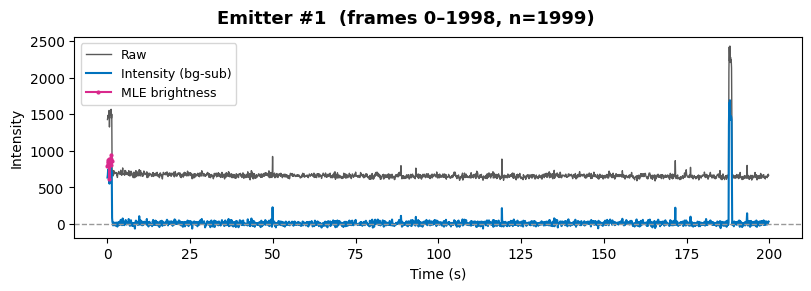

In [ ]:
from smlm.viz import check_trace
for i in range(1,2):
    # photons_i 长度 == emitters[i].frame.size(每个 localization 一个值)
    photons_i = corr_locs.photons[emitters[i].loc_idx]     # 按你的 Localizations 取法
    check_trace(traces[i], emitter=emitters[i], ex_time=raw.exposure_time,
                mle_brightness=photons_i, use_time=True,  show_track=False, panels='trace')

## Trace Analysis

In [ ]:
from smlm.trace import get_analyzer, analyze_traces, plot_state_gallery
specs = get_analyzer("changepoint").param_specs()
for name, (default, help_) in specs.items():
    print(f"{name:18s} = {default!r:12}  {help_}")

In [ ]:
results = analyze_traces(traces, method="changepoint",penalty=3, bleach_tail = 50)

In [ ]:
fig = plot_state_gallery(results, n_max=20)

In [ ]:
from smlm.trace import plot_summary
fig = plot_summary(results)